In [1]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

In [2]:
class State(TypedDict):
    # Messages have the type "List". The add_messages function in the annotation defines how the state key should be updated.
    # In our case, Appends the list, rather than overwriting.
    messages: Annotated[list, add_messages]

graph = StateGraph(State)

In [3]:
import os 
from dotenv import load_dotenv
load_dotenv()

True

In [4]:
from langchain.chat_models import init_chat_model
llm = init_chat_model("openrouter:liquid/lfm-2.5-2.6b:free")

In [5]:
def chatbot(state: State):
    return {"messages": [llm.invoke(state["messages"])]}

In [6]:
graph.add_node("llmchabot", chatbot)
graph.add_edge(START, "llmchabot")
graph.add_edge("llmchabot", END)
graph1 = graph.compile()

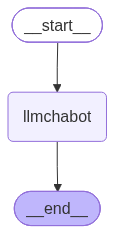

In [7]:
from IPython.display import Image,display

try:
    display(Image(graph1.get_graph().draw_mermaid_png()))
except:
    pass

In [8]:
# graph1.invoke("HI") # this will not work since we have defined a dict in our state
graph1.invoke({"messages":"Hi"})

{'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='4438594d-2578-4ed3-8371-c557a597d1d6'),
  AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "Hi". This is a simple greeting. I should respond in a friendly manner, perhaps ask how I can help them today. There\'s no policy violation. Just greet back and offer assistance.', 'reasoning_details': [{'type': 'reasoning.text', 'format': 'unknown', 'index': 0, 'text': 'The user says "Hi". This is a simple greeting. I should respond in a friendly manner, perhaps ask how I can help them today. There\'s no policy violation. Just greet back and offer assistance.'}]}, response_metadata={'model_name': 'liquid/lfm-2.5-2.6b:free', 'id': 'gen-1786970617-rgsnXfZ7kIyhdfGxKtEr', 'created': 1786970617, 'object': 'chat.completion', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'openrouter', 'cost': 0.0, 'cost_details': {'upstream_inference_complet

In [10]:
for event in graph1.stream({"messages":"Hi"}):
    print(event) # we will get the node and its functionality details
    for value in event.values():
        print(value) # we will get the messages, that too the AI messages.
        print(value["messages"][-1].content)

{'llmchabot': {'messages': [AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "Hi". This is a simple greeting. I should respond in a friendly manner, perhaps asking how I can help them today. There\'s no policy violation. Just greet back and offer assistance.', 'reasoning_details': [{'type': 'reasoning.text', 'format': 'unknown', 'index': 0, 'text': 'The user says "Hi". This is a simple greeting. I should respond in a friendly manner, perhaps asking how I can help them today. There\'s no policy violation. Just greet back and offer assistance.'}]}, response_metadata={'model_name': 'liquid/lfm-2.5-2.6b:free', 'id': 'gen-1786971049-F1SBNKW98fInH6DvJYw2', 'created': 1786971049, 'object': 'chat.completion', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'openrouter', 'cost': 0.0, 'cost_details': {'upstream_inference_completions_cost': 0.0, 'upstream_inference_prompt_cost': 0.0, 'upstream_inference_cost': 0.0}, 'system_

## Chatbot with Tools

In [ ]:
from langchain_tavily import tavily_search

tool = tavily_search(max_results=2)
tool.invoke("What is AI")

In [17]:
def multiply(a:int, b:int)->int:
    """
    Multiply a and b
    args:
        a (int): First Integer
        b (int): Second Integer
    Returns:
        int: which is the answer or output integer from multiplication.
    """
    return a*b

In [20]:
tools = [tool, multiply]
llm.bind_tools(tools)
llm_with_tools = llm.bind_tools(tools)

NameError: name 'tool' is not defined

In [19]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

def llm_with_tool(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

builder = StateGraph(State)
builder.add_node("llm_with_tool", llm_with_tool)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "llm_with_tool")
builder.add_conditional_edges(
    "llm_with_tool",
    tools_condition
)
builder.add_edge("tools", END)
graph2 = builder.compile()


NameError: name 'tools' is not defined

In [ ]:
from IPython.display import Image,display

try:
    display(Image(graph1.get_graph().draw_mermaid_png()))
except:
    pass

In [ ]:
response = graph.invoke({"messages": "What is the recent dollar pricee to inr"})

In [ ]:
for m in response["messages"]:
    m.pretty_print()

In [ ]:
response = graph.invoke({"messages": "What is the recent dollar pricee to inr and multiply 5 by 2"})
# This architecture will fail since after doing one call to the tool, then the graph reaches the END, due to which the second question goes unanswered.
# To overcome this, we need to use the ReAct architecture.
# Here after one tool call the result is given back to the llm and the llm becomes the decision maker for the next step.

NameError: name 'graph' is not defined

### ReAct Agent Architecture

In [ ]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

def llm_with_tool(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

builder = StateGraph(State)
builder.add_node("llm_with_tool", llm_with_tool)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "llm_with_tool")
builder.add_conditional_edges(
    "llm_with_tool",
    tools_condition
)
builder.add_edge("tools", "llm_with_tool") # ReAct architecture, after the tool call, the result is given back to the llm and the llm becomes the decision maker for the next step.
graph2 = builder.compile()


## Adding Memory in Agentic Graph

In [ ]:
# to overcome the issue of persistent checkpointing.

from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver

memeory = MemorySaver() # in-memory checkpoint saver, saves the previous chat informations.

def llm_with_tool(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

builder = StateGraph(State)
builder.add_node("llm_with_tool", llm_with_tool)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "llm_with_tool")
builder.add_conditional_edges(
    "llm_with_tool",
    tools_condition
)
builder.add_edge("tools", "llm_with_tool")
graph2 = builder.compile(checkpointer=memeory) # passing the checkpoint saver to the graph, so that it can save the previous chat informations.


In [ ]:
# we need to create threads for accessing the memory of the interactions.
config = {"configurable": {"thread_id": "1"}}
response = graph.invoke({"messages":"Hi"}, config=config)
# So now for this particular thread id, all the conversations we are having will be saved in the memory and we can access it later using the same thread id.

## Streaming in LangGraph

In [2]:
from langgraph.checkpoint.memory import MemorySaver

memeory = MemorySaver() # in-memory checkpoint saver, saves the previous chat informations.


In [3]:
def superbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

In [ ]:
graph = StateGraph(State)
graph.add_node("superbot", superbot)
graph.add_edge(START, "superbot")
graph.add_edge("superbot", END)
graph_builder = graph.compile(checkpointer=memeory) # passing the checkpoint saver to the graph, so that it can save the previous chat informations.


In [ ]:
config = {"configurable": {"thread_id": "1"}}
for chunk in graph_builder.stream({"messages":"Hi"}, config=config, stream_mode="updates"):
    print(chunk)
for chunk in graph_builder.stream({"messages":"Hi"}, config=config, stream_mode="values"):
    print(chunk)

In [ ]:
for chunk in graph_builder.astream_events({"messages":"Hi"}, config=config, version="1.2"):
    print(chunk)

## Human In The Loop